## Part 0

In [1]:
import sqlite3
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_percentage_error
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import adfuller
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.api import qqplot
import warnings
from statsmodels.tools.sm_exceptions import ConvergenceWarning

In [2]:
conn = sqlite3.connect('energy.db')
cursor = conn.cursor()

In [3]:
#get tables
cursor.execute("""
SELECT name FROM sqlite_master
WHERE type='table';
""")
cursor.fetchall()

[('usa_co2',), ('usa_demand',), ('usa_emissions',), ('usa_generation',)]

In [4]:
# get table columns
cursor.execute("""PRAGMA table_info(usa_emissions);""")
cursor.fetchall()

[(0, 'Date', 'TEXT', 0, None, 0),
 (1, 'Emissions (Fossil) (mtCO2)', 'REAL', 0, None, 0),
 (2, 'Emissions (Clean) (mtCO2)', 'REAL', 0, None, 0)]

In [5]:
#get table columns
cursor.execute("PRAGMA table_info(usa_demand);")
cursor.fetchall()

[(0, 'index', 'INTEGER', 0, None, 0),
 (1, 'Date', 'TEXT', 0, None, 0),
 (2, 'Demand (TWh)', 'REAL', 0, None, 0)]

In [6]:
#get table columns
cursor.execute("PRAGMA table_info(usa_co2);")
cursor.fetchall()

[(0, 'index', 'INTEGER', 0, None, 0),
 (1, 'Date', 'TEXT', 0, None, 0),
 (2, 'CO2 Intensity (gCO2/kWh)', 'REAL', 0, None, 0)]

In [7]:
#get table columns
cursor.execute("PRAGMA table_info(usa_generation);")
cursor.fetchall()

[(0, 'Date', 'TEXT', 0, None, 0),
 (1, 'Electricity generation (Fossil) (TWh)', 'REAL', 0, None, 0),
 (2, 'Electricity generation (Clean) (TWh)', 'REAL', 0, None, 0)]

In [8]:
query = """
SELECT
    e.Date,
    (e."Emissions (Fossil) (mtCO2)" + e."Emissions (Clean) (mtCO2)") AS Total_Emissions,
    d."Demand (TWh)" AS Total_Demand,
    c."CO2 Intensity (gCO2/kWH)" AS CO2_Intensity,
    (g."Electricity generation (Fossil) (TWh)" + g."Electricity generation (Clean) (TWh)") AS Total_Electricity_Generation
FROM usa_emissions e
JOIN usa_generation g ON e.Date = g.Date
JOIN usa_demand d ON e.Date = d.Date
JOIN usa_co2 c ON e.Date = c.Date
WHERE e.Date BETWEEN '2025-01-01' AND '2025-12-31'
ORDER BY e.Date ASC
"""

In [9]:
df_2025 = pd.read_sql_query(query,conn)

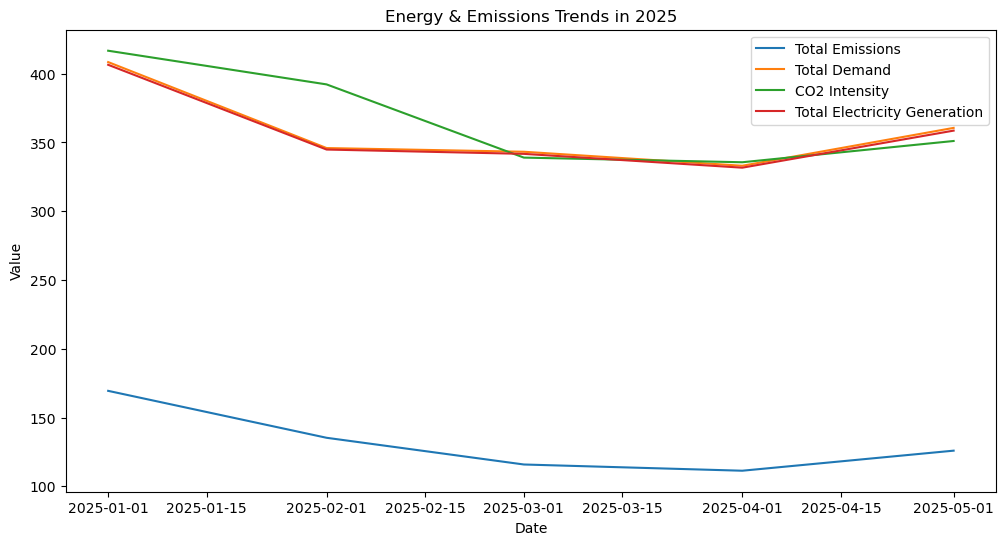

In [10]:
# make sure Date is datetime
df_2025["Date"] = pd.to_datetime(df_2025["Date"])

plt.figure(figsize=(12,6))

plt.plot(df_2025["Date"], df_2025["Total_Emissions"], label="Total Emissions")
plt.plot(df_2025["Date"], df_2025["Total_Demand"], label="Total Demand")
plt.plot(df_2025["Date"], df_2025["CO2_Intensity"], label="CO2 Intensity")
plt.plot(df_2025["Date"], df_2025["Total_Electricity_Generation"], label="Total Electricity Generation")

plt.title("Energy & Emissions Trends in 2025")
plt.xlabel("Date")
plt.ylabel("Value")
plt.legend()
plt.show()

All four categories including total emissions, total demand, CO2 Intensity, and total electicity generation start the year decreasing and finish up the year increasing. The data only goes until May, so it is unsure what the remainder of the calendar year would look like. I notice total demand and total electricity generation following just about the exact same pattern. CO2 intensity follows a similar trend but changes more gradually compared to demand and electricity generation. Then those two columns start to increase slightly quicker than CO2 intensity. Also, there is 3 different units being used in the data. demand and electricity use 'TWh', emissions uses mtCO2, and CO2 intensity uses gCO2/kWh.

## Part 1(Model the Relationship)

In [11]:
#query with all years(without WHERE)
all_years = """
SELECT
    e.Date,
    (e."Emissions (Fossil) (mtCO2)" + e."Emissions (Clean) (mtCO2)") AS Total_Emissions,
    d."Demand (TWh)" AS Total_Demand,
    c."CO2 Intensity (gCO2/kWH)" AS CO2_Intensity,
    (g."Electricity generation (Fossil) (TWh)" + g."Electricity generation (Clean) (TWh)") AS Total_Electricity_Generation
FROM usa_emissions e
JOIN usa_generation g ON e.Date = g.Date
JOIN usa_demand d ON e.Date = d.Date
JOIN usa_co2 c ON e.Date = c.Date
ORDER BY e.Date ASC
"""

In [12]:
df = pd.read_sql_query(all_years,conn)

In [13]:
df

,Date,Total_Emissions,Total_Demand,CO2_Intensity,Total_Electricity_Generation
0,2001-01-01,206.86,333.64,623.50,331.77
1,2001-02-01,172.51,282.77,611.07,282.31
2,2001-03-01,182.42,301.73,608.07,300.00
3,2001-04-01,168.65,279.89,607.73,277.51
4,2001-05-01,181.51,302.61,605.56,299.74
...,...,...,...,...,...
288,2025-01-01,169.40,408.47,416.73,406.50
289,2025-02-01,135.27,345.95,392.24,344.87
290,2025-03-01,115.85,343.27,339.01,341.73
291,2025-04-01,111.32,333.08,335.63,331.68


In [14]:
#making sure that monthly data is expected
cursor.execute("""SELECT Date FROM usa_emissions
WHERE Date LIKE '2025%'
""")
cursor.fetchall()

[('2025-01-01',),
 ('2025-02-01',),
 ('2025-03-01',),
 ('2025-04-01',),
 ('2025-05-01',)]

In [15]:
X = df[['Total_Demand','CO2_Intensity', 'Total_Electricity_Generation']]
y = df['Total_Emissions']

In [16]:
df['Date'] = pd.to_datetime(df['Date'])

In [17]:
train_mask = df['Date'].dt.year < 2022
test_mask  = df['Date'].dt.year >= 2022

In [18]:
X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

In [19]:
linreg = LinearRegression()
linreg.fit(X_train, y_train)
predictions = linreg.predict(X_test)

In [20]:
#MAPE
mape = mean_absolute_percentage_error(y_test, predictions) * 100
mape

2.75403773303971

My linear regression model achieved a MAPE of just over 2.75%, meaning predictions were off by about 2.75% on average. This demonstrates the model successfully captured the trend in emissions over the test period.

## Part 2(Forecast)

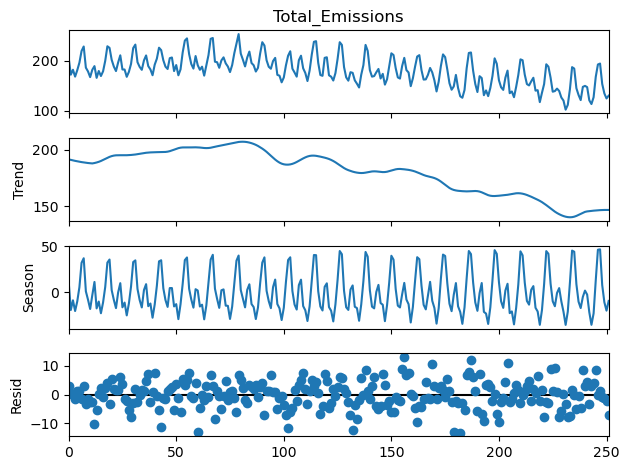

In [21]:
stl = STL(y_train, period=12).fit()
resid = stl.resid

stl.plot()
plt.show()

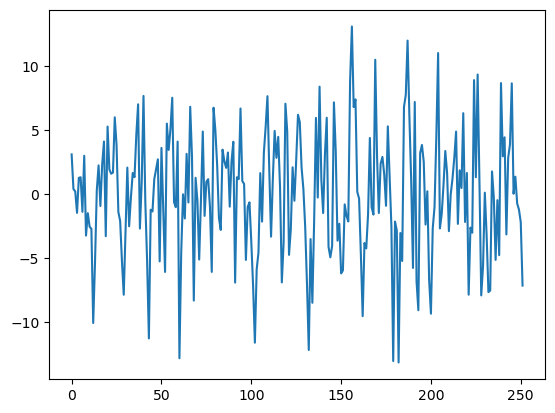

In [22]:
plt.plot(resid)

In [23]:
adfuller(resid)

(np.float64(-8.504358648763436),
 np.float64(1.214156731378107e-13),
 11,
 240,
 {'1%': np.float64(-3.4578942529658563),
  '5%': np.float64(-2.8736593200231484),
  '10%': np.float64(-2.573228767361111)},
 np.float64(1362.5960274412992))

This series is stationary because the p-value is < 0.05.

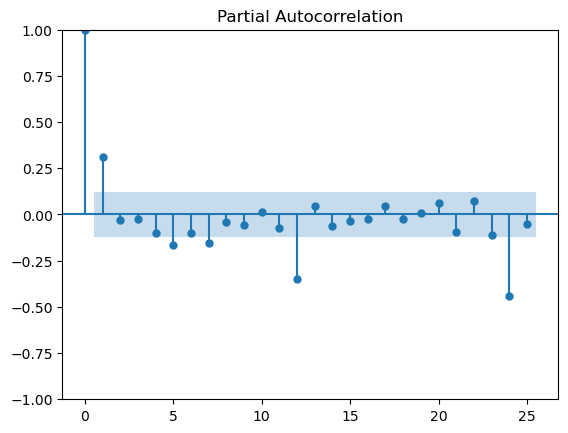

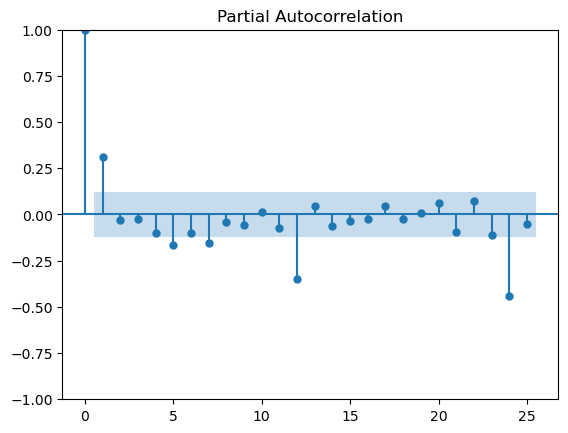

In [24]:
plot_pacf(resid)

The PACF plot shows a significant spike at lag 1 before dropping into the confidence band, suggesting an auto regressive component of order 1. However, using AIC value to compare models, ARIMA(3,0,2) produced the lowest AIC score so I selected that since AIC is the more reliable way to pick p and q for ARIMA models.

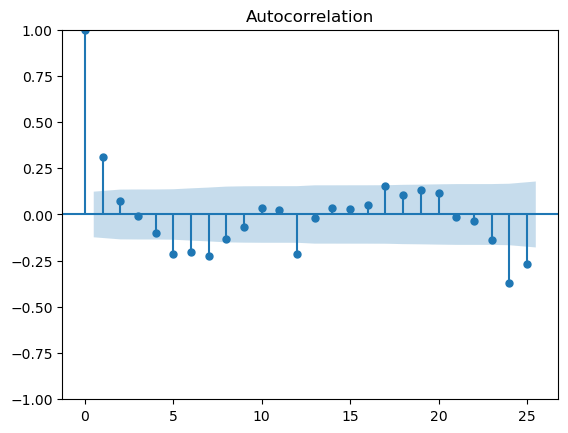

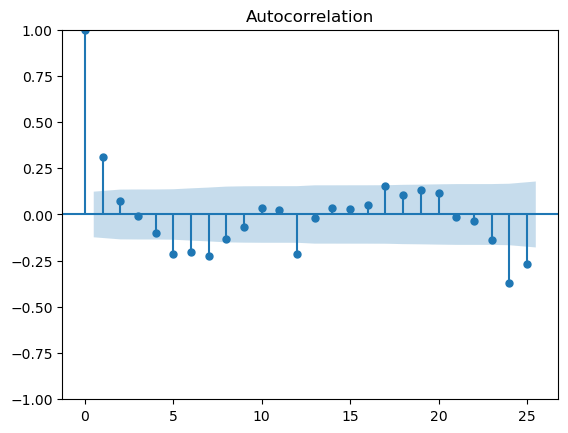

In [25]:
plot_acf(resid)

The ACF plot shows a significant spike at lag 1 before dropping into the confidence band at lag 2, suggesting a moving average component of order 1. However, AIC comparison across multiple models selected a moving average order of 2 as the best fit.

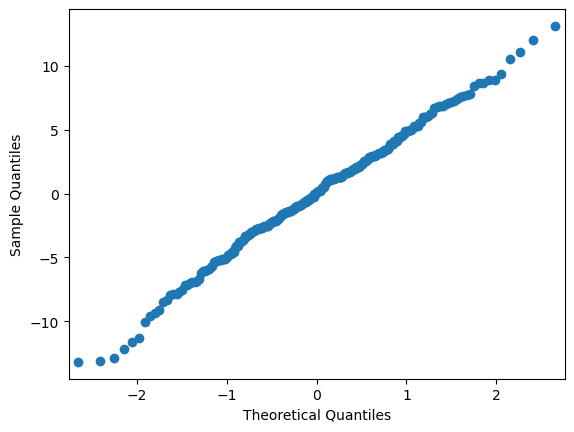

In [26]:
qqplot(resid)
plt.show()

The QQ plot shows the sample quantiles closely following the theoretical normal distribution quantiles, with only minor deviation at the tails. This suggests the residuals are approximately normally distributed.

In [27]:
#fit model on full training set to look at AIC before forecasting loop
model = ARIMA(y_train, order=(3,0,2)).fit(method_kwargs={"maxiter": 1000})
model.summary()

<class 'statsmodels.iolib.summary.Summary'>
"""
                               SARIMAX Results                                
==============================================================================
Dep. Variable:        Total_Emissions   No. Observations:                  252
Model:                 ARIMA(3, 0, 2)   Log Likelihood               -1006.955
Date:                Tue, 29 Sep 2026   AIC                           2027.911
Time:                        17:33:44   BIC                           2052.617
Sample:                             0   HQIC                          2037.852
                                - 252                                         
Covariance Type:                  opg                                         
==============================================================================
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const        180.3616      6.050     29.811      0.000     168.503     192.220
ar.L1          1.8545      0.036     51.729      0.000       1.784       1.925
ar.L2         -1.8544      0.036    -51.847      0.000      -1.924      -1.784
ar.L3          0.8552      0.035     24.746      0.000       0.787       0.923
ma.L1         -0.9777      0.399     -2.453      0.014      -1.759      -0.196
ma.L2          0.9992      0.856      1.168      0.243      -0.678       2.676
sigma2       165.5714    138.416      1.196      0.232    -105.719     436.862
===================================================================================
Ljung-Box (L1) (Q):                   0.12   Jarque-Bera (JB):                 3.13
Prob(Q):                              0.73   Prob(JB):                         0.21
Heteroskedasticity (H):               1.07   Skew:                            -0.26
Prob(H) (two-sided):                  0.77   Kurtosis:                         2.84
===================================================================================

Warnings:
[1] Covariance matrix calculated using the outer product of gradients (complex-step).
"""

In [ ]:
S = len(y_train)
Y = y.values 


warnings.filterwarnings("ignore", category=ConvergenceWarning)


y_pred = np.zeros_like(y_test)
for i in range(S, len(Y)):
    model = ARIMA(endog=Y[:i], order=(3,0,2)).fit()
    pred = model.get_forecast(steps=1).summary_frame()
    y_pred[i-S] = pred['mean'].iloc[0]

mape = mean_absolute_percentage_error(y_test, y_pred) * 100
mape

8.03629730053581

Using an ARIMA(3,0,2) model, I achieved a test set MAPE of approximately 8%, meaning predictions were off by around 8% on average.